## Data Science Project:

An Information Retrieval Engine


This notebook was designed on Google Colab. We recommend viewing it via Colab
to avoid any display issues with section titles and cell outputs.

#**Phase 1: Retrieval Basics:**


##**1. Data Exploration, Statistics, and Preparation**




**Importer le dataset de Kaggle**



In [ ]:
# Install the Kaggle API
!pip install -q kaggle

In [ ]:
# Import required libraries for data handling, text processing, and visualization

import json              # To read and write JSON files
import os                # To interact with the operating system (files, directories)
import sys               # To access system-specific parameters and functions
import regex as re       # Advanced regular expressions for text processing
import zipfile           # To extract and handle ZIP files
import pandas as pd      # Data manipulation and analysis (DataFrames)
import matplotlib.pyplot as plt  # Data visualization (plots and charts)
import numpy as np       # Numerical computing (arrays, mathematical operations)
from collections import Counter, defaultdict  # Counting and dictionary utilities
import statistics        # Basic statistical functions (mean, median, etc.)
import seaborn as sns    # Statistical data visualization built on Matplotlib

In [ ]:
# Kaggle credentials are read from environment variables (never commit your API key)
kaggle_token = {
    "username": os.environ.get("KAGGLE_USERNAME", "YOUR_KAGGLE_USERNAME"),
    "key": os.environ.get("KAGGLE_KEY", "YOUR_KAGGLE_KEY")
}

# Create the .kaggle directory (if it does not already exist)
os.makedirs("/root/.kaggle", exist_ok=True)

# Write the kaggle.json configuration file
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_token, f)

# Set the correct file permissions (read/write for the owner only)
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle configured successfully ✅")

Kaggle configured successfully ✅


In [ ]:
# Download the competition dataset from Kaggle
!kaggle competitions download -c retrieval-engine-competition

# Unzip the downloaded dataset (overwrite existing files if needed)
!unzip -o retrieval-engine-competition.zip

  0% 0.00/82.8M [00:00<?, ?B/s]
100% 82.8M/82.8M [00:00<00:00, 1.56GB/s]
Archive:  retrieval-engine-competition.zip
  inflating: docs.json               
  inflating: qgts_train.json         
  inflating: queries_test.json       
  inflating: queries_train.json      
  inflating: submission.csv          


In [ ]:
import json

# Load the documents dataset
with open("docs.json", "r") as f:
    documents = json.load(f)

# Load training queries
with open("queries_train.json", "r") as f:
    train_queries = json.load(f)

# Load relevance judgments (ground truth)
with open("qgts_train.json", "r") as f:
    gts = json.load(f)

# Load test queries
with open("queries_test.json", "r") as f:
    test_queries = json.load(f)

# Print dataset sizes
print("documents Number:", len(documents))
print("train queries Number:", len(train_queries))
print("relevance judgments Number:", len(gts))
print("test queries Number:", len(test_queries))

# Convert data to pandas DataFrames for easier manipulation
docs_df = pd.DataFrame(documents)
train_queries_df = pd.DataFrame(train_queries)
gts_df = pd.DataFrame(gts)
test_queries_df = pd.DataFrame(test_queries)

documents Number: 216041
train queries Number: 327
relevance judgments Number: 327
test queries Number: 141


### 1.1 Document Corpus (documents.json)

**Overview:**
Shape of the dataset, total number of documents (216,041), and unique categories.

In [ ]:
print("Shape:", docs_df.shape)
docs_df.head(5)

Shape: (216041, 5)


,id,text,title,tags,category
0,6970cbf2-ffff-4c7b-b73d-52524000c232_145427,I try to install Complete MiKTeX 2.9 But there...,MikTex Download Failure - toptesi.tar.lzma,[miktex],tex
1,667220d0-66be-4059-ae60-b9df15d285f7_77850,I'm trying to get a launcher working for the W...,Launcher for a Python program that requires ex...,"[gnome3, python, path, cd]",unix
2,e5608645-f23d-4cf4-bda6-46071510ebb0_84546,Its unclear as to whether this trait means tha...,"How does the ""Double damage in combat"" trait w...",[ftl-faster-than-light],gaming
3,367fcce1-2ed8-4a95-81e4-77e30c1a37eb_154499,I am writing a thesis with specific margin req...,"Compiling with ""latex"" instead of ""pdflatex"" c...","[margins, geometry]",tex
4,75fcda1e-9b8e-4d95-bbd9-770dd6f011cc_41849,I always see job positions for web companies f...,Machine Learning Web Jobs,"[job-definition, artificial-intelligence]",programmers


In [ ]:
print("total number of documents :", docs_df.shape[0])
print("total number of category :", docs_df["category"].nunique())
print("category list :", docs_df["category"].unique())

total number of documents : 216041
total number of category : 5
category list : ['tex' 'unix' 'gaming' 'programmers' 'android']


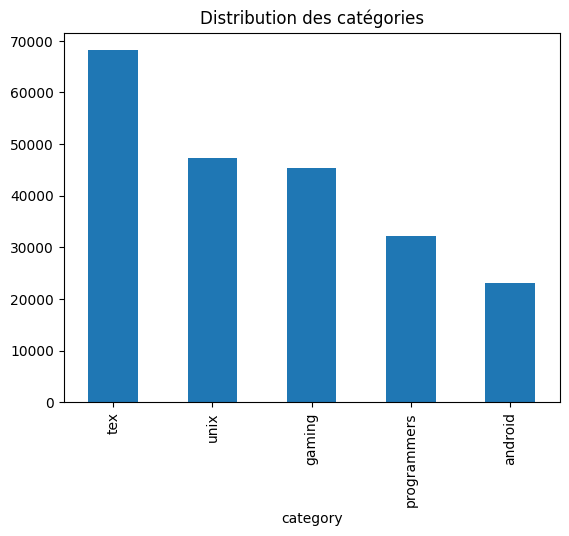

In [ ]:
#distribution of categoru
docs_df["category"].value_counts().plot(kind="bar")
plt.title("Distribution des catégories")
plt.show()

**Tag Statistics:**

Total unique tags (8,449), top 10 most frequent tags, and descriptive statistics of tags per document (Boxplot).

In [ ]:
tags_counts = dict()
for tags in docs_df["tags"]:
 for tag in tags:
  tags_counts[tag] = tags_counts.get(tag, 0) + 1
print(tags_counts.__len__(), "unique tag")
print("Most Frequent Tag :")
Counter(tags_counts).most_common(10)
docs_df["Tag#"] = docs_df["tags"].apply(lambda x: len(x))
docs_df["Tag#"].describe()

8449 unique tag
Most Frequent Tag :


,Tag#
count,216041.000000
mean,2.257215
std,1.140581
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,5.000000


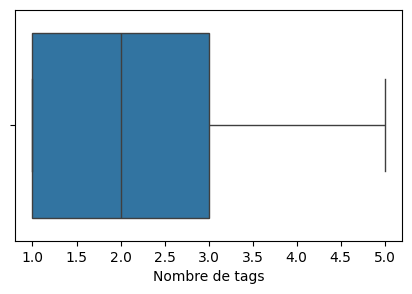

In [ ]:
plt.figure(figsize=(5, 3))
sns.boxplot(x=docs_df["Tag#"])
plt.xlabel("Nombre de tags")
plt.show()

**Data Integrity**:
* Missing Values Count of NAs
* identification of blank strings (e.g., the document with ID 34477 has a blank text field).

In [ ]:
# Count missing values per column
na_counts = docs_df.isna().sum()

# Compute percentage of missing values
na_pct = (na_counts / len(docs_df) * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "missing_count": na_counts,
    "missing_pct": na_pct
})

# Sort columns by number of missing values (descending)
missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_pct
id,0,0.0
text,0,0.0
title,0,0.0
tags,0,0.0
category,0,0.0
Tag#,0,0.0


In [ ]:
# --- Small preprocessing step for clean data exploration ---

import re

# Check if a string is empty (after stripping spaces)
def is_blank_str(x):
    return isinstance(x, str) and x.strip() == ""

# Check if text is too short or contains only special characters
def is_quasi_empty_text(x, min_chars=5):
    if not isinstance(x, str):
        return False

    cleaned = x.strip()

    # Text is considered quasi-empty if very short
    if len(cleaned) < min_chars:
        return True

    # Or if it contains only non-alphanumeric characters
    if re.match(r'^\W+$', cleaned):
        return True

    return False

# Validate tags (must be a non-empty list of non-empty strings)
def is_bad_tags(x):
    if not isinstance(x, list):
        return True
    if len(x) == 0:
        return True

    # Clean tags
    cleaned_tags = [t.strip() for t in x if isinstance(t, str)]
    cleaned_tags = [t for t in cleaned_tags if t != ""]

    return len(cleaned_tags) == 0

# Check if text field has invalid type
def is_bad_type_text(x):
    return not isinstance(x, str)


# --- Basic data quality checks on documents ---

blank_title = docs_df["title"].apply(is_blank_str).sum()
blank_text  = docs_df["text"].apply(is_blank_str).sum()

quasi_empty_text = docs_df["text"].apply(is_quasi_empty_text).sum()

empty_or_bad_tags = docs_df["tags"].apply(is_bad_tags).sum()

bad_type_text = docs_df["text"].apply(is_bad_type_text).sum()

empty_categories = docs_df["category"].apply(is_blank_str).sum()

# Display exploration results
print("Blank title:", blank_title)
print("Blank text :", blank_text)
print("Quasi-empty text (short/punct only):", quasi_empty_text)
print("Empty or bad tags:", empty_or_bad_tags)
print("Bad type in text:", bad_type_text)
print("Empty categories :", empty_categories)

Blank title: 0
Blank text : 1
Quasi-empty text (short/punct only): 1
Empty or bad tags: 0
Bad type in text: 0
Empty categories : 0


In [ ]:
blank_text_rows = docs_df[docs_df["text"].apply(is_blank_str)]
print("Blank text rows:")
display(blank_text_rows)

quasi_empty_text_rows = docs_df[docs_df["text"].apply(is_quasi_empty_text)]
print("\nQuasi-empty text rows (short/punct only):")
display(quasi_empty_text_rows)

Blank text rows:


,id,text,title,tags,category,Tag#
34477,12193f6f-c8a8-4d30-9917-5f32cc0c2a31_245,,"Where can I find the ""mutant donkey woman"" horse?",[red-dead-redemption],gaming,1



Quasi-empty text rows (short/punct only):


,id,text,title,tags,category,Tag#
34477,12193f6f-c8a8-4d30-9917-5f32cc0c2a31_245,,"Where can I find the ""mutant donkey woman"" horse?",[red-dead-redemption],gaming,1


In [ ]:
# Install the word2number library (convert written numbers to digits)
!pip install word2number

  Preparing metadata (setup.py) ... done
  Created wheel for word2number: filename=word2number-1.1-py3-none-any.whl size=5568 sha256=d317ba6597c0bafd9397da8b7864248eded45a6ca6177e9c7d6ef30376c87c91
  Stored in directory: /root/.cache/pip/wheels/5b/79/fb/d25928e599c7e11fe4e00d32048cd74933f34a74c633d2aea6
Successfully built word2number


**Data Preparation for Documents analysis**

For Text:
* Numerical Normalization: Conversion of numbers written in letters to their numerical values.

* Lowercasing: Conversion of all characters to lowercase.

*  Special Character Removal: Stripping out non-alphanumeric characters and symbols.


For Tags:
* Special Character Removal: Elimination of symbols and punctuation within the tags.

* Empty and Duplicate Removal: Deletion of empty tags and removal of redundant entries.

* Tag Sorting: Alphabetical sorting of tags to handle consistency (e.g., "margins, geometry" and "geometry, margins").

In [ ]:
import re
import pandas as pd
from word2number import w2n

# Convert written numbers (e.g., "twenty five") into digits
def replace_num(match):
    try:
        return str(w2n.word_to_num(match.group(0)))
    except:
        # Keep original text if conversion fails
        return match.group(0)

# Clean and normalize text
def clean_text(s):
    if pd.isna(s):
        return ""

    # Convert to lowercase
    s = str(s).lower()

    # Define number word patterns
    units = r"(?:one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|thirteen|fourteen|fifteen|sixteen|seventeen|eighteen|nineteen)"
    tens = r"(?:twenty|thirty|forty|fifty|sixty|seventy|eighty|ninety)"
    scales = r"(?:hundred|thousand|million|billion)"

    num_pattern = rf"\b(?:{units}|{tens}|{scales})(?:[\s\-]|and|{units}|{tens}|{scales})*\b"

    # Replace number words with digits
    s = re.sub(num_pattern, replace_num, s, flags=re.IGNORECASE)

    # Remove special characters (keep letters and digits only)
    s = re.sub(r"[^a-z0-9]", " ", s)

    # Normalize whitespace
    s = re.sub(r"\s+", " ", s).strip()

    return s

# Clean and normalize a list of tags
def clean_tags(tags):
    if not isinstance(tags, list):
        return ""

    cleaned = [clean_text(t) for t in tags]  # Clean each tag
    cleaned = [t for t in cleaned if t != ""]  # Remove empty tags
    cleaned = sorted(set(cleaned))  # Remove duplicates and sort

    return " ".join(cleaned)  # Return as a single string

In [ ]:
# Apply text cleaning to document titles
docs_df["title_clean"] = docs_df["title"].apply(clean_text)

# Apply text cleaning to document main text
docs_df["text_clean"] = docs_df["text"].apply(clean_text)

# Apply tag cleaning to document tags
docs_df["tags_clean"] = docs_df["tags"].apply(clean_tags)

In [ ]:
#merging Title, Text, and Tags into  Content_key

#Increasing title importance by tripling its frequency: docs_df["title_clean"]+ " ")*3

docs_df["content_key"] = (
    (docs_df["title_clean"]+ " ")*3 +
    docs_df["text_clean"]  + " " +
    docs_df["tags_clean"]
).str.strip()

**Analysis of Potential Duplicates:**

Duplicate Doc IDs: Multiple records sharing the same unique identifier.

Duplicate Doc Titles: Different documents that have the exact same title.

Duplicate Doc Text: Instances where the body content is identical across different entries.

Duplicate Content Keys: Rows where the combination of Title, Tags, and Text is identical (indicating a 100% semantic match).




In [ ]:
dup_id = docs_df["id"].str.strip().duplicated().sum()
print("Duplicated doc IDs (after stripping spaces):", dup_id)

Duplicated doc IDs (after stripping spaces): 0


In [ ]:
dup_title = docs_df["title_clean"].duplicated().sum()
print("Duplicated doc title:", dup_title)

Duplicated doc title: 115


In [ ]:
#affichage des titres doublés
docs_df[docs_df["title_clean"].duplicated(keep=False)].sort_values("title_clean").head(len(docs_df[docs_df["title_clean"].duplicated(keep=False)]))

,id,text,title,tags,category,Tag#,title_clean,text_clean,tags_clean,content_key
194827,2ddfc7a8-2abe-4460-bdba-326137299df4_82661,I'm facing a problem with ABD connection under...,adb connection problem on Kubuntu 13.04 x64,"[android, kubuntu]",unix,2,adb connection problem on kubuntu 13 04 x64,i m facing a problem with abd connection under...,android kubuntu,adb connection problem on kubuntu 13 04 x64 ad...
178521,24644441-3fb6-49ea-82cf-320d5156209b_48826,I'm facing a problem with ABD connection under...,adb connection problem on Kubuntu 13.04 x64,"[adb, linux]",android,2,adb connection problem on kubuntu 13 04 x64,i m facing a problem with abd connection under...,adb linux,adb connection problem on kubuntu 13 04 x64 ad...
196455,6134a3d2-df51-486e-b41a-e85820ae3ff1_49509,I have my own self-signed SSL certificate for ...,Adding a self-signed certificate to the truste...,"[certificates, https]",android,2,adding a self signed certificate to the truste...,i have my own self signed ssl certificate for ...,certificates https,adding a self signed certificate to the truste...
168797,427c35d6-bb57-495e-8bc6-0cba8ebb0c72_90450,I've generated a self-signed certificate for m...,"Adding a self-signed certificate to the ""trust...",[ssl],unix,1,adding a self signed certificate to the truste...,i ve generated a self signed certificate for m...,ssl,adding a self signed certificate to the truste...
73246,1fdedf98-93eb-4d64-be06-434cbd0e4821_151727,I am trying to align the 2 equals signs and th...,Alignment issue?,"[horizontal-alignment, errors, vertical-alignm...",tex,3,alignment issue,i am trying to align the 2 equals signs and th...,errors horizontal alignment vertical alignment,alignment issue alignment issue alignment issu...
...,...,...,...,...,...,...,...,...,...,...
155999,8232f17d-734d-4420-84fb-fa5369f1425e_82035,I am trying to choose the right license for a ...,Which open-source license is right for my proj...,"[php, open-source, licensing]",programmers,3,which open source license is right for my project,i am trying to choose the right license for a ...,licensing open source php,which open source license is right for my proj...
167259,75783b70-ed3c-4d0d-bd5f-bc0fc01f3d1b_176148,this time I'm writing my Bachelor Thesis on Un...,Wrong Sorting nomenclature and predefined vari...,[nomenclature],tex,1,wrong sorting nomenclature and predefined vari...,this time i m writing my bachelor thesis on un...,nomenclature,wrong sorting nomenclature and predefined vari...
4676,5f4c44eb-814a-4d38-ad21-47c1f0b43bb2_176222,This time I'm writing my Bachelor Thesis on Un...,Wrong Sorting nomenclature and predefined vari...,[nomenclature],tex,1,wrong sorting nomenclature and predefined vari...,this time i m writing my bachelor thesis on un...,nomenclature,wrong sorting nomenclature and predefined vari...
90068,575b4a5c-e093-426b-a165-bf672ddab8eb_82197,Pls help me! I got some error message in TeXni...,You can't use `\eqno' in math mode,[errors],tex,1,you can t use eqno in math mode,pls help me i got some error message in texnic...,errors,you can t use eqno in math mode you can t use ...


In [ ]:
dup_text = docs_df["text_clean"].duplicated().sum()
print("Duplicated doc text:", dup_text)

Duplicated doc text: 39


In [ ]:
#affichage des text doublés
docs_df[docs_df["text_clean"].duplicated(keep=False)].sort_values("text_clean").head(39)

,id,text,title,tags,category,Tag#,title_clean,text_clean,tags_clean,content_key
116371,a1e43c46-4d07-469c-940d-42c0905aff90_110968,After exporting `HISTTIMEFORMAT='%F %T'` I tri...,Changing HISTTIMEFORMAT leaves entries with in...,"[bash, command-history]",unix,2,changing histtimeformat leaves entries with in...,after exporting histtimeformat f t i tried to ...,bash command history,changing histtimeformat leaves entries with in...
105858,89d4a21b-4c94-4d72-9293-fa9672179cd2_87740,After exporting `HISTTIMEFORMAT='%F %T'` I tri...,HISTTIMEFORMAT does not show correct date and ...,"[bash, command-history]",unix,2,histtimeformat does not show correct date and ...,after exporting histtimeformat f t i tried to ...,bash command history,histtimeformat does not show correct date and ...
109726,e5e58a01-c99e-4b25-9c53-e5c1966b6b60_3225,And to what extent does this card have support...,Is the Creative Sound Blaster X-FI Surround 5....,"[linux, audio, drivers]",unix,3,is the creative sound blaster x fi surround 5 ...,and to what extent does this card have support...,audio drivers linux,is the creative sound blaster x fi surround 5 ...
23836,9077fc57-36db-410b-bbec-a39427e4e941_3222,And to what extent does this card have support...,Is the Zalman ZM-RSSC 5.1 USB Sound Card suppo...,[audio],unix,1,is the zalman zm rssc 5 1 usb sound card suppo...,and to what extent does this card have support...,audio,is the zalman zm rssc 5 1 usb sound card suppo...
83411,402b7c74-43c6-4204-8157-286c45b5c6bc_62945,Anyone know of any simple Template for scienti...,Lyx template for scientific paper,"[templates, lyx]",tex,2,lyx template for scientific paper,anyone know of any simple template for scienti...,lyx templates,lyx template for scientific paper lyx template...
86806,7e713eeb-67c1-4c07-9a7d-a1c69d583f26_3669,Anyone know of any simple Template for scienti...,Lyx template for scientific paper,"[pdftex, templates, lyx]",tex,3,lyx template for scientific paper,anyone know of any simple template for scienti...,lyx pdftex templates,lyx template for scientific paper lyx template...
67646,44b7c6c2-417c-4c74-9011-cf66a7ec9629_95865,"Basically, what I did: 1. Copied vmail folde...",Is it possible to import vmail folder from old...,"[ubuntu, email, mysql, postgresql, dovecot]",unix,5,is it possible to import vmail folder from old...,basically what i did 1 copied vmail folder to ...,dovecot email mysql postgresql ubuntu,is it possible to import vmail folder from old...
215013,1cb697bb-a3ac-4a49-ac9c-9ce8bbaebc20_96557,"Basically, what I did: 1. Copied vmail folde...",Is it possible to import vmail folder from old...,"[email, ubuntu, migration, dovecot]",unix,4,is it possible to import vmail folder from old...,basically what i did 1 copied vmail folder to ...,dovecot email migration ubuntu,is it possible to import vmail folder from old...
166677,36adda0d-9b58-43bf-9de8-4ca234090a10_13101,"by standard, i mean just what users often get ...",how do I get most of my standard linux utiliti...,"[applications, linux, 3.1-honeycomb]",android,3,how do i get most of my standard linux utiliti...,by standard i mean just what users often get b...,3 1 honeycomb applications linux,how do i get most of my standard linux utiliti...
28477,3b962d89-4c2d-40e2-88ad-4439e49a9e6f_20109,"By standard, I mean just what users often get ...",How do I get most of my standard Linux utiliti...,"[linux, android]",unix,2,how do i get most of my standard linux utiliti...,by standard i mean just what users often get b...,android linux,how do i get most of my standard linux utiliti...


In [ ]:
dup_content = docs_df["content_key"].duplicated().sum()
print("Duplicated documents (normalized content):", dup_content)

Duplicated documents (normalized content): 4


In [ ]:
duplicates = docs_df[docs_df["content_key"].duplicated(keep=False)]
duplicates[["id", "category", "content_key"]].head(10)

,id,category,content_key
0,6970cbf2-ffff-4c7b-b73d-52524000c232_145427,tex,miktex download failure toptesi tar lzma mikte...
11550,adb7e709-e31b-44af-9b5f-6d8c7f957b22_118893,unix,installing amd radeon hd 7400m series fedora 2...
64762,d66a76a1-e1eb-4664-be39-742cba57fe03_144168,tex,miktex download failure toptesi tar lzma mikte...
86975,64fb0eeb-8e35-49ae-a0c5-fa2f6f7b0e22_62073,android,high frequency noise from headphones when conn...
128238,69e4813f-1098-48e5-981c-70c6593c592b_62130,android,high frequency noise from headphones when conn...
130527,531bc409-badc-4003-916e-d3a935d80703_117112,unix,installing amd radeon hd 7400m series fedora 2...
173695,3ff97c15-6666-4a0d-9ce1-cc17d03ad3f4_19710,tex,how can i set the maximum number of rows in a ...
200577,ddbaf37f-41b3-4e4c-a954-83dde6e68469_52784,tex,how can i set the maximum number of rows in a ...


**Length analysis (number of words) :**

In [ ]:
docs_df["content_raw"] = (
    docs_df["title"].astype(str) + " " +
    docs_df["text"].astype(str)  + " " +
    docs_df["tags"].apply(lambda t: " ".join(sorted(t)))
).str.strip()


docs_df["doc_length_raw"] = docs_df["content_raw"].apply(lambda x: len(str(x).split()))


docs_df["doc_length"] = docs_df["content_key"].apply(lambda x: len(str(x).split()))

print("docs Number:", docs_df.shape[0])

print("\nLength Stat (RAW) :")
print(docs_df["doc_length_raw"].describe())

print("\nLength Stat  (CLEAN) :")
print(docs_df["doc_length"].describe())

docs Number: 216041

Length Stat (RAW) :
count    216041.000000
mean        137.182234
std         146.971431
min           9.000000
25%          64.000000
50%         100.000000
75%         161.000000
max        5256.000000
Name: doc_length_raw, dtype: float64

Length Stat  (CLEAN) :
count    216041.000000
mean        172.896358
std         191.751597
min          15.000000
25%          86.000000
50%         127.000000
75%         197.000000
max        8932.000000
Name: doc_length, dtype: float64


In [ ]:
short_docs = (docs_df["doc_length"] < 50).sum()
medium_docs = ((docs_df["doc_length"] >= 50) & (docs_df["doc_length"] < 200)).sum()
long_docs = (docs_df["doc_length"] >= 200).sum()

print("\nDistribution by size :")
print("Short documents (<50 words) :", short_docs)
print("Medium documents (50-200 words) :", medium_docs)
print("Long documents (>200 words) :", long_docs)


Distribution by size :
Short documents (<50 words) : 7353
Medium documents (50-200 words) : 155859
Long documents (>200 words) : 52829


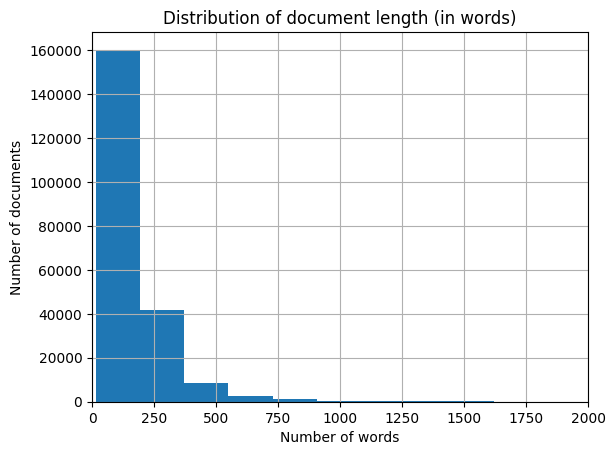

In [ ]:


plt.figure()
docs_df["doc_length"].hist(bins=50)
plt.xlim(0, 2000)
plt.title("Distribution of document length (in words)")
plt.xlabel("Number of words")
plt.ylabel("Number of documents")
plt.show()

In [ ]:
# top 5 plus longs
docs_df.sort_values("doc_length", ascending=False).head(5)[
    ["id", "doc_length", "category"]
]

,id,doc_length,category
107453,b2dab658-08dc-4af3-8edf-e05142a71592_82295,8909,tex
38602,061d2c60-30eb-4683-8d9f-f9ae06324873_166854,8501,tex
190322,ffcde7de-c243-40e7-8efc-97116860e0d4_28739,6028,unix
35756,7f7399cb-3c1b-497a-bc51-c2ff8a828f0a_150066,5512,tex
108632,5085a430-e486-4c70-9919-104598fda909_24973,5451,unix


In [ ]:
#top 5 plus courts
docs_df.sort_values("doc_length", ascending=True).head(5)[
    ["id", "doc_length", "category"]
]

,id,doc_length,category
136317,e0dabfc7-cfb6-43ea-b6d8-3c8895666d77_28549,9,tex
135963,268abc0b-4645-4101-a3b3-745d6d97d361_5910,11,unix
171528,1058c223-1889-4fcd-bc2e-398a0c7bd469_10482,11,gaming
201662,36d6d1b3-cbdf-42a6-897b-a4f4b78cebea_642,11,gaming
27907,850c2934-833c-4baf-916f-745a2b4bb482_16239,11,android


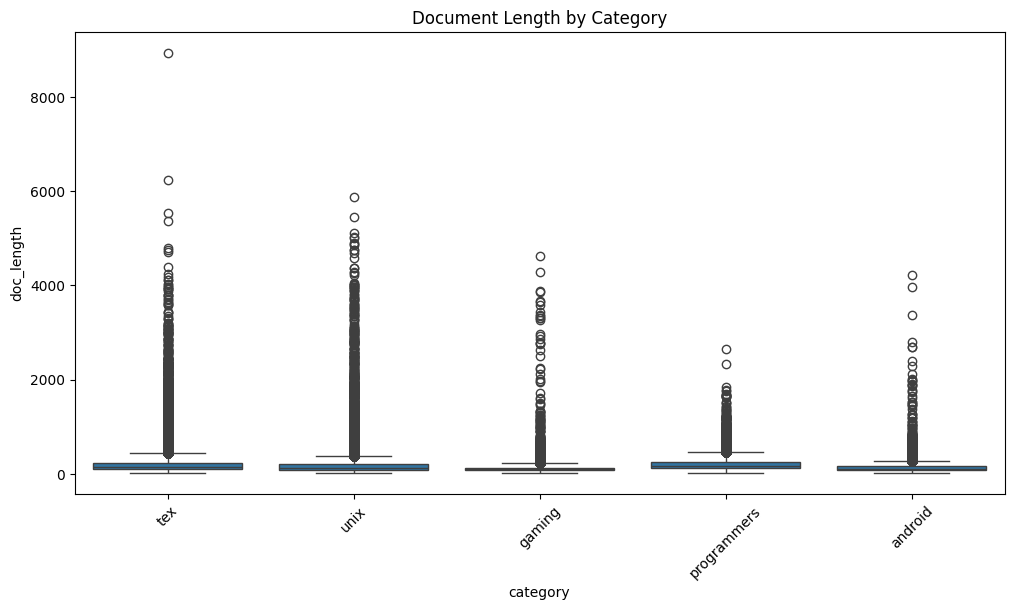

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(x="category", y="doc_length", data=docs_df)
plt.xticks(rotation=45)
plt.title("Document Length by Category")
plt.show()

In [ ]:
Q1 = docs_df["doc_length"].quantile(0.25)
Q3 = docs_df["doc_length"].quantile(0.75)
IQR = Q3 - Q1

outliers = docs_df[docs_df["doc_length"] > Q3 + 1.5 * IQR]

print("Nombre de documents outliers :", len(outliers))
outliers[["id", "doc_length"]].head()


Nombre de documents outliers : 14800


,id,doc_length
6,b25af998-bcb1-4988-93a7-0eb06f6781ce_113704,654
23,72c5b815-261e-4e3d-8238-b36f2470c142_81766,393
30,32f70c9b-feba-40e4-af1f-1c323a3d8c35_62230,708
35,024e2ca7-2df5-4580-9927-a38dd25a6234_151011,554
60,af07f4bd-743e-4e47-a560-65de82448afb_146927,413


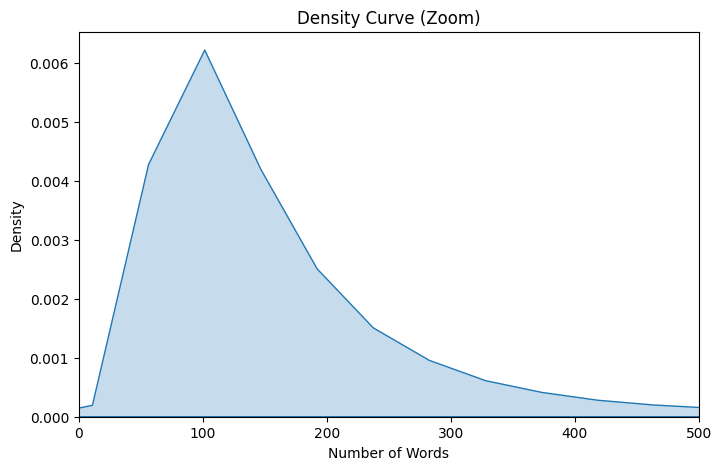

In [ ]:
plt.figure(figsize=(8,5))
sns.kdeplot(docs_df["doc_length"], fill=True)

plt.xlim(0, 500)  # zoom
plt.title("Density Curve (Zoom)")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.show()

### 1.2 Train Queries (train_queries.json)

**Overview:**

Shape (327 queries) and category distribution

In [ ]:
print("Shape:", train_queries_df.shape)
train_queries_df.head(10)

Shape: (327, 5)


,id,text,title,tags,category
0,961c4349-8cf1-4ef1-89cc-24d20bb9d000_67878,Want to try reformatting Damaged SD Card,,"[linux, development]",android
1,4008ed78-e66e-4d89-9c3b-c79bd1cf6fc9_366,"Convince grep to output all lines, not just th...",,"[shell, virtualization, storage, cluster]",unix
2,d5a95b09-e8ea-44dd-993d-347ed418e1f1_15138,How can I automatically reject some types of c...,,"[linux, development]",android
3,3e66798a-b7fd-41b5-8bc0-33b3d7ce2aca_177487,Left and right braces on different lines of align,,"[tikz-pgf, horizontal-alignment, tikz-trees]",tex
4,f5f944d2-277a-481d-ab09-612890402ded_137489,How do you get the purple shark fin?,,[skyrim],gaming
5,da11c342-a2b4-442b-a95a-b2c26f78bf7a_194764,Highlighting labels of undefined citations?,,"[tikz-pgf, horizontal-alignment, tikz-trees]",tex
6,980c09bc-14a0-4832-ad0b-ac1a79ca51cd_55670,\href without decoration (no underline),,"[tikz-pgf, horizontal-alignment, tikz-trees]",tex
7,e655782b-869d-4d80-9513-fda43a2bbf84_54069,"Rooting - how to, and what are the consequence...",,"[linux, development]",android
8,cc1235a9-a603-4891-8474-6cc0a860f159_84759,Which PDF viewers for Linux support Beamer's s...,,"[tikz-pgf, horizontal-alignment, tikz-trees]",tex
9,534caa94-be3a-4a61-b39e-5319f0f9425c_28551,Why can't android connect to an ad hoc hotspot?,,"[linux, development]",android


In [ ]:
train_queries_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 327 entries, 0 to 326
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        327 non-null    object
 1   text      327 non-null    object
 2   title     327 non-null    object
 3   tags      327 non-null    object
 4   category  327 non-null    object
dtypes: object(5)
memory usage: 12.9+ KB


In [ ]:
print("Total number of categories :", train_queries_df["category"].nunique())
print("List of categories :", train_queries_df["category"].unique())

Total number of categories : 5
List of categories : ['android' 'unix' 'tex' 'gaming' 'programmers']


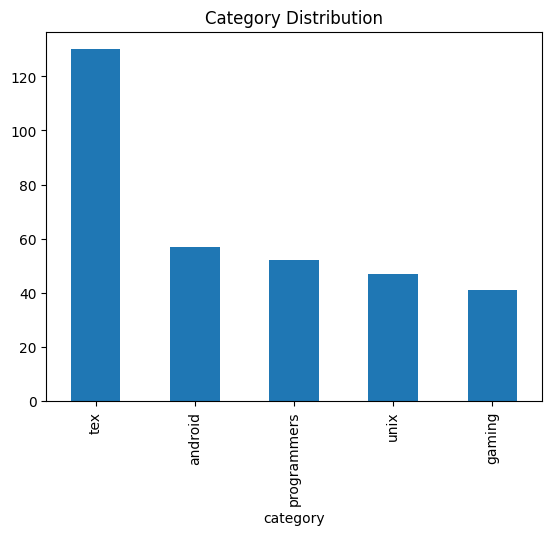

In [ ]:
train_queries_df["category"].value_counts().plot(kind="bar")
plt.title("Category Distribution")
plt.show()

**Tag Analysis:**

Statistics of unique tags (only 15 for queries) and distribution of tags per query.

In [ ]:
tags_countsq = dict()
for tags in train_queries_df["tags"]:
 for tag in tags:
  tags_countsq[tag] = tags_countsq.get(tag, 0) + 1

print(tags_countsq.__len__(), "unique tag")
print("Top 10 most frequent tags :")
Counter(tags_countsq).most_common(10)

15 unique tag
Top 10 most frequent tags :


[('tikz-pgf', 130),
 ('horizontal-alignment', 130),
 ('tikz-trees', 130),
 ('linux', 57),
 ('development', 57),
 ('web-development', 52),
 ('python', 52),
 ('sql', 52),
 ('concurrency', 52),
 ('sqlite', 52)]

In [ ]:
train_queries_df["Tag#"] = train_queries_df["tags"].apply(lambda x: len(x))
train_queries_df["Tag#"].describe()

,Tag#
count,327.000000
mean,3.036697
std,1.207796
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000


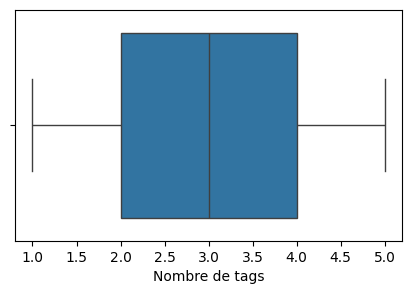

In [ ]:
plt.figure(figsize=(5, 3))
sns.boxplot(x=train_queries_df["Tag#"])
plt.xlabel("Nombre de tags")
plt.show()

In [ ]:
na_countsq = train_queries_df.isna().sum()
na_pctq = (na_countsq / len(train_queries_df) * 100).round(2)
missing_summaryq = pd.DataFrame({"missing_count": na_countsq, "missing_pct": na_pctq})
missing_summaryq.sort_values("missing_count", ascending=False)

,missing_count,missing_pct
id,0,0.0
text,0,0.0
title,0,0.0
tags,0,0.0
category,0,0.0
Tag#,0,0.0


**Data Integrity:**

Check for NAs, blank titles, and potential duplicates.

In [ ]:
blank_titleq = train_queries_df["title"].apply(is_blank_str).sum()
blank_textq  = train_queries_df["text"].apply(is_blank_str).sum()

quasi_empty_textq = train_queries_df["text"].apply(is_quasi_empty_text).sum()



empty_or_bad_tagsq = train_queries_df["tags"].apply(is_bad_tags).sum()

bad_type_textq = train_queries_df["text"].apply(is_bad_type_text).sum()

empty_categoriesq = train_queries_df["category"].apply(is_blank_str).sum()


print("Blank title:", blank_titleq)
print("Blank text :", blank_textq)
print("Quasi-empty text (short/punct only):", quasi_empty_textq)
print("Empty or bad tags:", empty_or_bad_tagsq)
print("Bad type in text:", bad_type_textq)
print("Empty categories :", empty_categoriesq)

Blank title: 327
Blank text : 0
Quasi-empty text (short/punct only): 0
Empty or bad tags: 0
Bad type in text: 0
Empty categories : 0


In [ ]:


train_queries_df["title_clean"] = train_queries_df["title"].apply(clean_text)

# Apply text cleaning to document main text
train_queries_df["text_clean"] = train_queries_df["text"].apply(clean_text)

# Apply tag cleaning to document tags
train_queries_df["tags_clean"] = train_queries_df["tags"].apply(clean_tags)


train_queries_df["content_key"] = (
    (train_queries_df["title_clean"] + " ") * 3 +   # Boost title weight
    train_queries_df["text_clean"] + " " +          # Add main text
    train_queries_df["tags_clean"]                  # Add tags
).str.strip()  # Remove extra spaces



dup_id_q = train_queries_df["id"].str.strip().duplicated().sum()
print("Duplicated doc IDs (after stripping spaces):", dup_id_q)
dup_text_q = train_queries_df["text_clean"].duplicated().sum()
print("Duplicated doc text:", dup_text_q)
dup_content_q = train_queries_df["content_key"].duplicated().sum()
print("Duplicated documents (normalized content):", dup_content_q)
train_queries_df["train_query_length"] = train_queries_df["content_key"].apply(lambda x: len(x.split())) #split en mots


Duplicated doc IDs (after stripping spaces): 0
Duplicated doc text: 0
Duplicated documents (normalized content): 0


**Length analysis :**

In [ ]:
train_queries_df["content_raw"] = (
    train_queries_df["title"].fillna("").astype(str) + " " +
    train_queries_df["text"].fillna("").astype(str)  + " " +
    train_queries_df["tags"].apply(lambda t: " ".join(t) if isinstance(t, list) else "")
).str.strip()

train_queries_df["train_length_raw"] = train_queries_df["content_raw"].apply(lambda x: len(str(x).split()))


print("Total number of queries :", train_queries_df.shape[0])

print("\nLength Statistics (RAW) :")
print(train_queries_df["train_query_length"].describe())

print("\nLength Statistics (CLEAN) :")
print(train_queries_df["train_query_length"].describe())

Total number of queries : 327

Length Statistics (RAW) :
count    327.000000
mean      12.899083
std        4.016710
min        3.000000
25%       10.000000
50%       12.000000
75%       15.000000
max       32.000000
Name: train_query_length, dtype: float64

Length Statistics (CLEAN) :
count    327.000000
mean      12.899083
std        4.016710
min        3.000000
25%       10.000000
50%       12.000000
75%       15.000000
max       32.000000
Name: train_query_length, dtype: float64


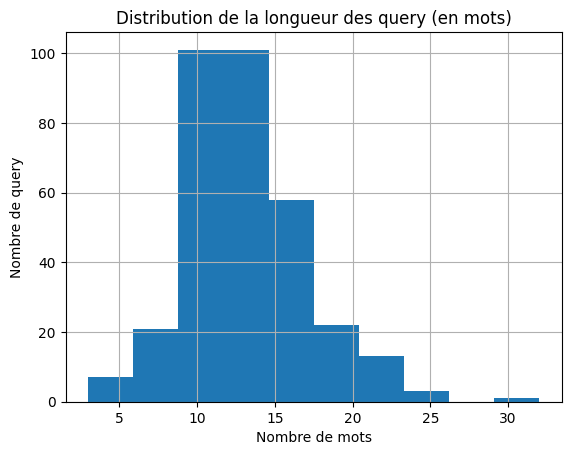

In [ ]:
plt.figure()
train_queries_df["train_query_length"].hist(bins=10)
plt.title("Distribution de la longueur des query (en mots)")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de query")
plt.show()

In [ ]:
#top 5 plus longs
train_queries_df.sort_values("train_query_length", ascending=False).head(5)[
    ["id", "train_query_length", "category"]
]

,id,train_query_length,category
128,14407185-5f1f-461d-8921-205f00c5cce7_211678,32,programmers
162,be509f2b-24ea-4ad2-8fa2-3c1261747ece_20653,26,programmers
180,96c242d4-dd2d-45b5-9706-4b741a31bb09_102552,25,tex
92,a9ad41a3-0147-424f-8a8f-a79feda99f5f_78501,24,unix
216,c4f18ca1-77f0-498e-9078-c657488270c2_98654,23,tex


In [ ]:
#top 5 plus courts
train_queries_df.sort_values("train_query_length", ascending=True).head(5)[
    ["id", "train_query_length", "category"]
]

,id,train_query_length,category
149,3617f665-9e52-4490-b8ac-031c71983732_160548,3,gaming
47,47d3232f-f7ec-4e71-a97f-942bc4cd2b7a_120032,4,gaming
154,769e411a-d0c0-4789-9a18-603bf01c6079_148895,4,gaming
24,55e9aab1-4705-44dc-9ce6-a9d9e8ffca3b_102361,5,gaming
134,a705a67a-f608-448d-9c76-772304c24f81_54068,5,gaming


In [ ]:
train_queries_df.sort_values("train_query_length", ascending=True).head(10)[["id", "train_query_length", "category", "text_clean", "tags_clean"]]

,id,train_query_length,category,text_clean,tags_clean
149,3617f665-9e52-4490-b8ac-031c71983732_160548,3,gaming,minecraft multiplayer,skyrim
47,47d3232f-f7ec-4e71-a97f-942bc4cd2b7a_120032,4,gaming,true vault huntermode,skyrim
154,769e411a-d0c0-4789-9a18-603bf01c6079_148895,4,gaming,redirecting nether portals,skyrim
134,a705a67a-f608-448d-9c76-772304c24f81_54068,5,gaming,point of no return,skyrim
146,6e78e67a-764b-48cf-b31d-dc6bc4153d84_87004,5,gaming,help with item stats,skyrim
24,55e9aab1-4705-44dc-9ce6-a9d9e8ffca3b_102361,5,gaming,diablo 3 monster curses,skyrim
106,da6c3298-b9a0-47d8-98ca-3ce2846fe2b0_82179,5,android,charging related question,development linux
202,71c6f22c-4b16-4b5e-af85-1885c716b892_161568,6,gaming,importing games back into steam,skyrim
224,e5603ca2-4cf8-4710-86a9-331bb1a9185d_21311,6,gaming,starting in world of warcraft,skyrim
41,0a490233-6a3a-4f2e-b61e-4260abfcb4c4_77444,6,android,bluetooth headset using android,development linux


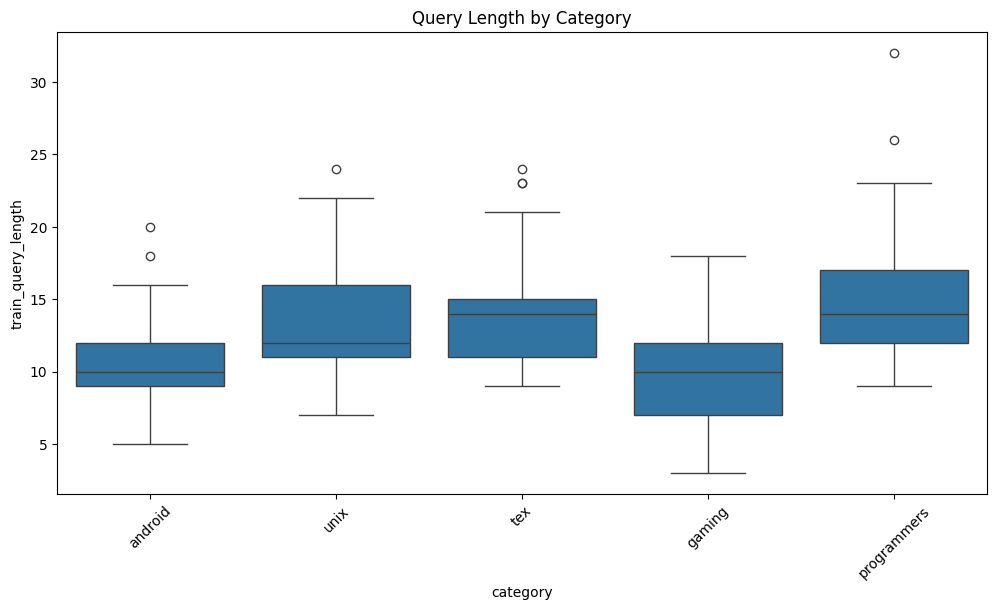

In [ ]:
import seaborn as sns

plt.figure(figsize=(12,6))
sns.boxplot(x="category", y="train_query_length", data=train_queries_df)
plt.xticks(rotation=45)
plt.title("Query Length by Category")
plt.show()

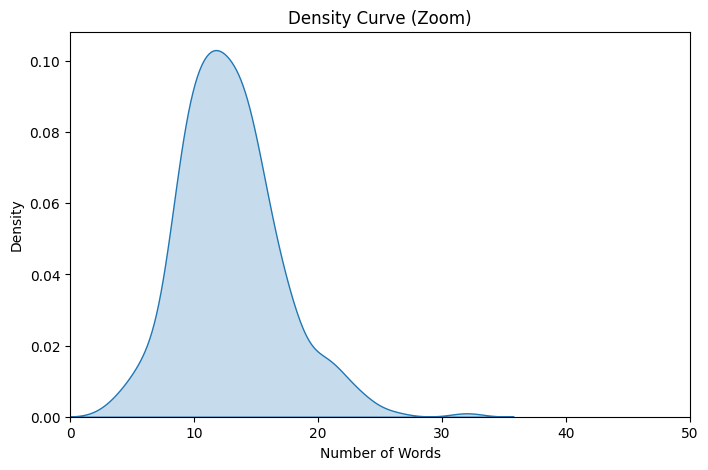

In [ ]:
plt.figure(figsize=(8,5))
sns.kdeplot(train_queries_df["train_query_length"], fill=True)

plt.xlim(0, 50)
plt.title("Density Curve (Zoom)")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.show()

### 1.3 Test Queries (test_queries.json)


**Overview:**

Shape (141 queries) and verification of schema similarity with training queries.


In [ ]:
print("Shape:", test_queries_df.shape)
test_queries_df.head(10)

Shape: (141, 4)


,id,text,title,tags
0,4ffe16bc-5235-418d-9bf3-22d1f2c5796e_145437,Why use an interface when the class can direct...,,"[web-development, python, sql, concurrency, sq..."
1,1bb2bb20-7f45-4dcf-a94a-420c454f87b8_56473,Linux isn't sure whether a file exists or not,,"[shell, virtualization, storage, cluster]"
2,6a9a342c-1275-4bb3-a818-8bcce53fac4f_34507,Will my Android device change to Gingerbread w...,,"[linux, development]"
3,cb216e47-add6-41fd-974a-39251e4df3aa_6777,How to clean up file extensions?,,"[shell, virtualization, storage, cluster]"
4,14f1d3f5-8271-400e-9ef2-8319de25c9a1_200748,Cancelling in a Fraction,,"[tikz-pgf, horizontal-alignment, tikz-trees]"
5,9ceab16a-79cf-4523-8846-ef2f9bbf2aad_40876,"How to get rid of the ""In:"" prefix in some bib...",,"[tikz-pgf, horizontal-alignment, tikz-trees]"
6,6ca71ddc-5bbf-4643-b789-6b5401e7673f_16078,How to force Gmail/Android to request password...,,"[linux, development]"
7,4b5622f5-566f-4dfa-b83a-f1b646381c06_186377,Developers taking code home - how bad is it?,,"[web-development, python, sql, concurrency, sq..."
8,009b1511-1254-4ee9-b697-f219d2c0bf4a_111002,What's the difference between $$ $$ and \begin...,,"[tikz-pgf, horizontal-alignment, tikz-trees]"
9,6cb18019-528d-4b41-ba49-1d92e4edbab2_9944,What is the difference between software engine...,,"[web-development, python, sql, concurrency, sq..."


In [ ]:
test_queries_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141 entries, 0 to 140
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      141 non-null    object
 1   text    141 non-null    object
 2   title   141 non-null    object
 3   tags    141 non-null    object
dtypes: object(4)
memory usage: 4.5+ KB


**Tag Statistics:**
Statistics of unique tags (only 15 for queries) and distribution of tags per query.

In [ ]:
tags_countst = dict()
for tags in test_queries_df["tags"]:
 for tag in tags:
  tags_countst[tag] = tags_countst.get(tag, 0) + 1

print(tags_countst.__len__(), "tags uniques")
print("Top 10 tags les plus fréquents :")
Counter(tags_countst).most_common(10)

15 tags uniques
Top 10 tags les plus fréquents :


[('tikz-pgf', 68),
 ('horizontal-alignment', 68),
 ('tikz-trees', 68),
 ('linux', 23),
 ('development', 23),
 ('shell', 19),
 ('virtualization', 19),
 ('storage', 19),
 ('cluster', 19),
 ('web-development', 17)]

In [ ]:
test_queries_df["Tag#"] = test_queries_df["tags"].apply(lambda x: len(x))
test_queries_df["Tag#"].describe()

,Tag#
count,141.000000
mean,3.014184
std,1.088812
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000


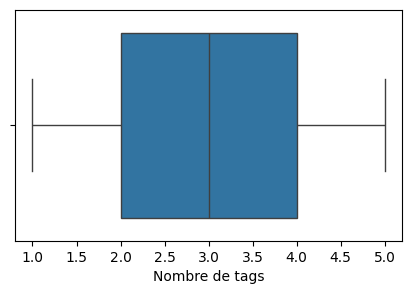

In [ ]:
plt.figure(figsize=(5, 3))
sns.boxplot(x=test_queries_df["Tag#"])
plt.xlabel("Nombre de tags")
plt.show()

**Data Integrity:**

Check for NAs, blank titles, and potential duplicates

In [ ]:
na_countst = test_queries_df.isna().sum()
na_pctt = (na_countst / len(test_queries_df) * 100).round(2)
missing_summaryt = pd.DataFrame({"missing_count": na_countst, "missing_pct": na_pctt})
missing_summaryt.sort_values("missing_count", ascending=False)

,missing_count,missing_pct
id,0,0.0
text,0,0.0
title,0,0.0
tags,0,0.0
Tag#,0,0.0


In [ ]:
blank_titlet = test_queries_df["title"].apply(is_blank_str).sum()
blank_textt  = test_queries_df["text"].apply(is_blank_str).sum()

quasi_empty_textt = test_queries_df["text"].apply(is_quasi_empty_text).sum()

empty_or_bad_tagst = test_queries_df["tags"].apply(is_bad_tags).sum()

bad_type_textt = test_queries_df["text"].apply(is_bad_type_text).sum()


print("Blank title:", blank_titlet)
print("Blank text :", blank_textt)
print("Quasi-empty text (short/punct only):", quasi_empty_textt)
print("Empty or bad tags:", empty_or_bad_tagst)
print("Bad type in text:", bad_type_textt)

Blank title: 141
Blank text : 0
Quasi-empty text (short/punct only): 0
Empty or bad tags: 0
Bad type in text: 0


**Length analysis:**

In [ ]:

test_queries_df["title_clean"] = test_queries_df["title"].apply(clean_text)

# Apply text cleaning to document main text
test_queries_df["text_clean"] = test_queries_df["text"].apply(clean_text)

# Apply tag cleaning to document tags
test_queries_df["tags_clean"] = test_queries_df["tags"].apply(clean_tags)


test_queries_df["content_key"] = (
    (test_queries_df["title_clean"] + " ") * 3 +   # Boost title weight
    test_queries_df["text_clean"] + " " +          # Add main text
    test_queries_df["tags_clean"]                  # Add tags
).str.strip()  # Remove extra spaces



test_queries_df["test_query_length"] = test_queries_df["content_key"].apply(lambda x: len(x.split())-2)

In [ ]:
print("\nStats test query lenghth :")
print(test_queries_df["test_query_length"].describe())


Stats test query lenghth :
count    141.000000
mean      11.070922
std        4.302234
min        1.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       25.000000
Name: test_query_length, dtype: float64


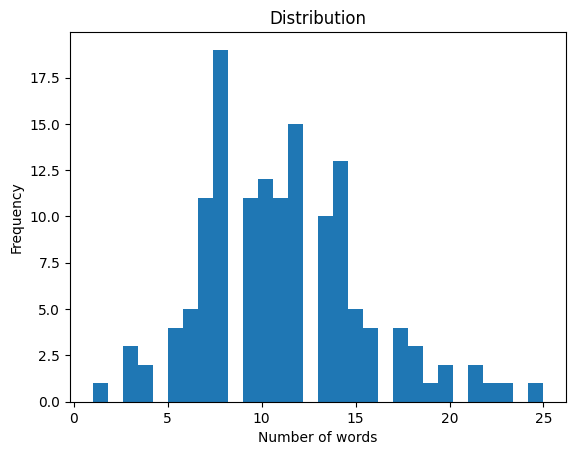

In [ ]:
plt.hist(test_queries_df["test_query_length"], bins=30)
plt.title("Distribution")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()

In [ ]:
#top 5 plus longs
test_queries_df.sort_values("test_query_length", ascending=False).head(5)[
    ["id", "test_query_length", "text_clean", "tags_clean"]
]

,id,test_query_length,text_clean,tags_clean
94,de3ebf94-4fd4-4c40-8fef-93e8b0ed1a3c_3955,27,is there a site where i can enter a latex expr...,horizontal alignment tikz pgf tikz trees
67,efd261f9-6aee-426e-a111-503120b649e6_82227,25,programming practice - is there a site that ha...,concurrency python sql sqlite web development
56,328b6d12-6289-46ec-b6c0-6be446e12d74_42934,25,is there a package for segmenting a large tex ...,horizontal alignment tikz pgf tikz trees
84,34fd1c44-93e0-45cd-8bed-7fc6bec4de81_111881,23,how much do i need to learn in order to get an...,concurrency python sql sqlite web development
114,8de9bb65-94c4-4321-bf7d-45bde732c59f_195456,23,what is the latex command or package that allo...,horizontal alignment tikz pgf tikz trees


In [ ]:
#top 5 plus courts
test_queries_df.sort_values("test_query_length", ascending=True).head(5)[
    ["id", "test_query_length", "text_clean", "tags_clean"]
]

,id,test_query_length,text_clean,tags_clean
32,21e8deec-77b4-429e-8129-6b4ac59d85ea_183174,3,mod installation,skyrim
57,69d3418a-c3c8-47d6-ab04-a9e1be9ce5a2_147878,5,follower missing in skyrim,skyrim
132,5961d629-54e6-4082-a5fb-6fcf35a06a1b_75755,5,android play store,development linux
135,2496e470-68f6-4d9f-b2dc-4526d72af391_26238,5,sms thread retrieval,development linux
52,b13578bd-e1f5-4aab-bdc2-1bf84b0ea1d2_137211,6,what use are chocolate bars,skyrim


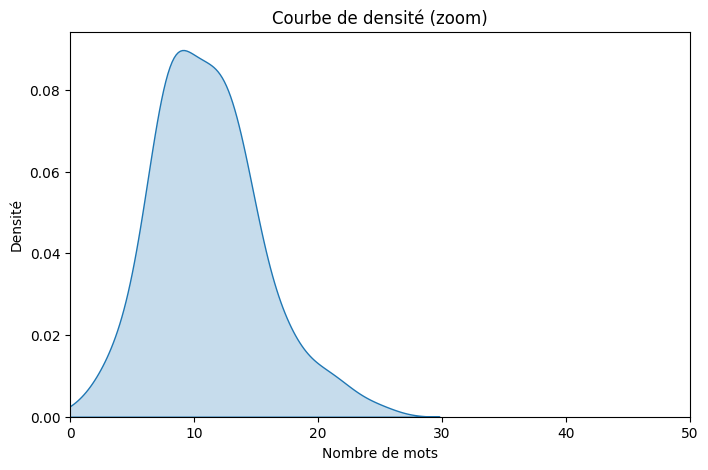

In [ ]:
plt.figure(figsize=(8,5))
sns.kdeplot(test_queries_df["test_query_length"], fill=True)

plt.xlim(0, 50)
plt.title("Courbe de densité (zoom)")
plt.xlabel("Nombre de mots")
plt.ylabel("Densité")
plt.show()


After analysis, we can conclude that train and test queries are similar.

It is important to note that our exploration of the test queries is strictly limited to
verifying the similarity between the two datasets.

We do not use any information from queries_test.json for model training or hyperparameter tuning, as this would result
in Data Leakage.

###1.4 Ground Truth (qgts_train.json)

**Overview and basic stats :**
- Shape (327 items)
- number of document relevant per query

In [ ]:
# Aperçu global
print("Shape:", gts_df.shape)
gts_df.head(10) #10 premiéres lignes

Shape: (3, 327)


,961c4349-8cf1-4ef1-89cc-24d20bb9d000_67878,4008ed78-e66e-4d89-9c3b-c79bd1cf6fc9_366,d5a95b09-e8ea-44dd-993d-347ed418e1f1_15138,3e66798a-b7fd-41b5-8bc0-33b3d7ce2aca_177487,f5f944d2-277a-481d-ab09-612890402ded_137489,da11c342-a2b4-442b-a95a-b2c26f78bf7a_194764,980c09bc-14a0-4832-ad0b-ac1a79ca51cd_55670,e655782b-869d-4d80-9513-fda43a2bbf84_54069,cc1235a9-a603-4891-8474-6cc0a860f159_84759,534caa94-be3a-4a61-b39e-5319f0f9425c_28551,...,cbd9045d-9abb-4103-9b45-64678a9b9262_185783,553912ab-4932-4d42-a047-b68aa507ee73_104362,1ed89f09-9d35-4668-8e05-7ffa10d0bd6c_206755,f73b0a9e-63c1-44cd-b36f-b41b696d4131_37581,46cddbe6-646c-4845-a699-7cdfe3b21721_65261,6f98ccbb-db6f-4646-ac1e-08d8d8bda71a_247103,345e8385-635c-44ab-abd1-f9fbcccaf774_159755,c38ac583-a824-46d9-ad00-105571c0c8fa_120087,3ed0fa3e-af7c-40b2-b44e-bf16de45051e_7772,7878104c-6dfa-42fe-badd-8fc53b2314ac_163896
total_relevant_docs,4,5,4,15,6,4,9,8,4,5,...,4,7,5,11,5,4,5,5,5,4
relevant_doc_ids,[{'doc_id': '135f5fdb-bcba-40b8-b90d-823617f1e...,[{'doc_id': 'ada9aadc-7371-450f-b610-9c1b40c8b...,[{'doc_id': 'ed189b8f-e6fe-42e3-b326-333b86d97...,[{'doc_id': 'a98df142-fd9e-4aad-a9c4-a334262e9...,[{'doc_id': '77294dfe-cbbb-4802-99ef-b86c2bd63...,[{'doc_id': '4016915f-5aee-4b97-94a0-02e998db6...,[{'doc_id': '0b4c1ceb-1a07-48d4-a555-f76e24058...,[{'doc_id': '124064f8-0dcf-4034-868d-2b16055ac...,[{'doc_id': '7bdf2f89-f3ab-4240-95d4-4616fe913...,[{'doc_id': '7b8283aa-a41e-41f9-bf7d-901ce326a...,...,[{'doc_id': '351d1ced-dc50-4e4f-90de-0d2684e64...,[{'doc_id': 'd770f2ef-2570-4b43-ae4b-75a99500d...,[{'doc_id': '28332c8d-5d96-4877-8429-d602a3735...,[{'doc_id': '6b4c155c-80d7-4203-9e62-e65f67aa2...,[{'doc_id': '99d38d5a-2d11-4ec2-b443-442e0d0eb...,[{'doc_id': '7ae6f7f5-b4ca-477a-b71e-8a8ae204c...,[{'doc_id': '142b4234-ce1b-4ba3-bc89-de7a57105...,[{'doc_id': 'f4dde969-74fc-4401-848d-ac1c906f7...,[{'doc_id': '43e3229a-7db0-423a-8557-10aabb32e...,[{'doc_id': '849eb92b-1401-430a-86ef-9fdfb09e2...
category,android,unix,android,tex,gaming,tex,tex,android,tex,android,...,tex,gaming,programmers,tex,android,programmers,tex,gaming,unix,gaming


In [ ]:
print("Number of docments in gts :", gts_df.shape[1])

Number of docments in gts : 327


In [ ]:
relevant_counts = gts_df.loc["total_relevant_docs"]
print(relevant_counts.head())

961c4349-8cf1-4ef1-89cc-24d20bb9d000_67878      4
4008ed78-e66e-4d89-9c3b-c79bd1cf6fc9_366        5
d5a95b09-e8ea-44dd-993d-347ed418e1f1_15138      4
3e66798a-b7fd-41b5-8bc0-33b3d7ce2aca_177487    15
f5f944d2-277a-481d-ab09-612890402ded_137489     6
Name: total_relevant_docs, dtype: object


In [ ]:
print("Statistiques nombre de documents pertinents par query :")
print(relevant_counts.describe())

Statistiques nombre de documents pertinents par query :
count     327
unique     31
top         4
freq      118
Name: total_relevant_docs, dtype: int64


In [ ]:
print("Nombre total de queries :", relevant_counts.count())
print("Minimum docs pertinents :", relevant_counts.min())
print("Maximum docs pertinents :", relevant_counts.max())
print("Moyenne :", relevant_counts.mean())
print("Médiane :", relevant_counts.median())

print("Queries avec 1 doc pertinent :", (relevant_counts == 1).sum())
print("Queries avec 0 doc pertinent :", (relevant_counts == 0).sum())
print("Queries avec >10 docs pertinents :", (relevant_counts > 10).sum())

Nombre total de queries : 327
Minimum docs pertinents : 4
Maximum docs pertinents : 262
Moyenne : 9.082568807339449
Médiane : 5.0
Queries avec 1 doc pertinent : 0
Queries avec 0 doc pertinent : 0
Queries avec >10 docs pertinents : 50


In [ ]:

print("Querry with most docs :")
print(relevant_counts.sort_values(ascending=False).head(10))

Querry with most docs :
49d7dae2-44cf-433f-beaf-b399905b27db_19971     262
6e3570f7-a217-4ece-a58a-ba973460c3aa_3747      149
69277e6f-e701-4859-aa63-54c6f18658ad_279       139
dba66105-2d70-4dd0-84c1-170cdb458cdb_44220      53
3a37f860-64bd-466b-a0b3-e98620382fff_168547     43
441f6e89-f077-42c1-a809-a608a3e05f1b_12834      42
0015b462-21fb-4413-97a6-30f13f879691_47598      40
cb347760-0693-41ca-9b9f-fe8a7834a027_56848      32
8a7889e0-b89f-4f6a-b984-f4d271a26c1c_82993      32
641962a5-c4a5-42b1-b7b6-16b9e34fc7fa_150072     30
Name: total_relevant_docs, dtype: object


**Distribution of relevant documents per querry**

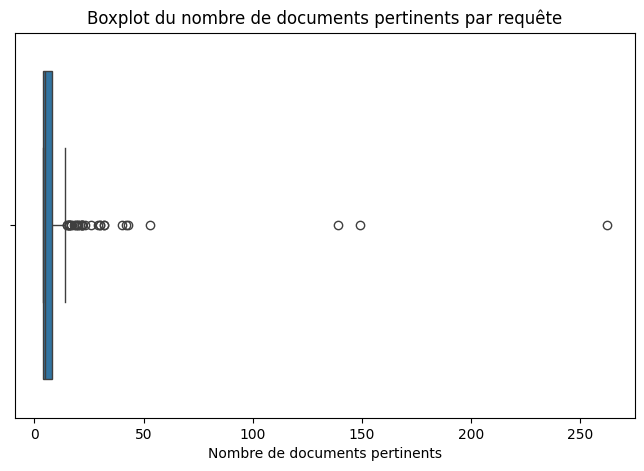

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x=relevant_counts.astype(int))
plt.title("Boxplot du nombre de documents pertinents par requête")
plt.xlabel("Nombre de documents pertinents")
plt.show()

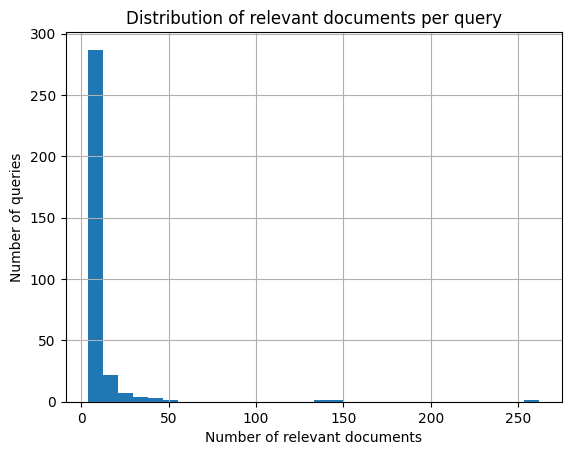

In [ ]:
plt.figure()
relevant_counts.hist(bins=30)
plt.title("Distribution of relevant documents per query")
plt.xlabel("Number of relevant documents")
plt.ylabel("Number of queries")
plt.show()

In [ ]:
categories_gts = gts_df.loc['category']
print("Category Number :", categories_gts.nunique())
print("Category List :", categories_gts.unique())

Category Number : 5
Category List : ['android' 'unix' 'tex' 'gaming' 'programmers']


In [ ]:
print("Category distribution By Querry :")
print(categories_gts.value_counts())

Category distribution By Querry :
category
tex            130
android         57
programmers     52
unix            47
gaming          41
Name: count, dtype: int64


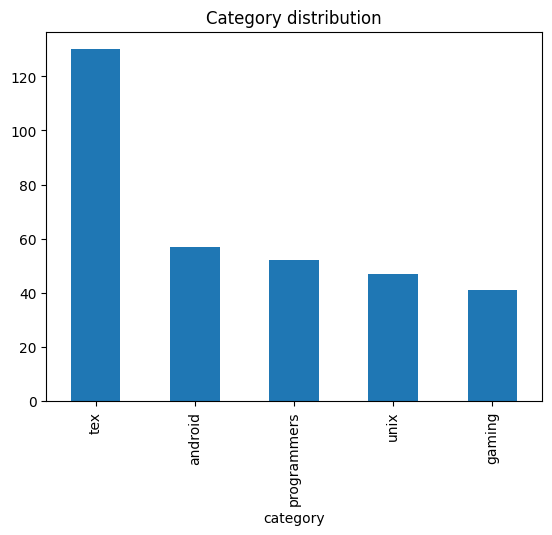

In [ ]:
categories_gts.value_counts().plot(kind="bar")
plt.title("Category distribution")
plt.show()

In [ ]:
analysis_df = pd.DataFrame({
    "num_relevant": relevant_counts,
    "category": categories_gts
})

print(analysis_df.groupby("category")["num_relevant"].describe())

             count  unique  top  freq
category                             
android         57      14    4    21
gaming          41      10    4    16
programmers     52      14    4    14
tex            130      21    4    48
unix            47      10    4    19


In [ ]:
# Vérifier les NaN spécifiquement dans les lignes 'category' et 'relevant_doc_ids'
nan_in_category = gts_df.loc['category'].isna().sum()
nan_in_relevant_doc_ids = gts_df.loc['relevant_doc_ids'].isna().sum()
print(f"NaNs dans la ligne 'category': {nan_in_category}")
print(f"NaNs dans la ligne 'relevant_doc_ids': {nan_in_relevant_doc_ids}")

# Vérifier les chaînes vides dans la ligne 'category'
empty_category_entries = gts_df.loc['category'].apply(lambda x: isinstance(x, str) and x.strip() == "").sum()
print(f"Chaînes vides dans la ligne 'category': {empty_category_entries}")

# Vérifier les listes vides dans la ligne 'relevant_doc_ids'
empty_relevant_doc_ids_entries = gts_df.loc['relevant_doc_ids'].apply(lambda x: isinstance(x, list) and len(x) == 0).sum()
print(f"Listes vides dans la ligne 'relevant_doc_ids': {empty_relevant_doc_ids_entries}")

NaNs dans la ligne 'category': 0
NaNs dans la ligne 'relevant_doc_ids': 0
Chaînes vides dans la ligne 'category': 0
Listes vides dans la ligne 'relevant_doc_ids': 0


In [ ]:
# Vérifier les doublons dans les IDs de requête (noms des colonnes)
dup_query_ids_gts = gts_df.columns.duplicated().sum()
print(f"Nombre d'IDs de requête dupliqués dans gts_df : {dup_query_ids_gts}")


Nombre d'IDs de requête dupliqués dans gts_df : 0


###1.5 Data Preparation

Before entering our data into the model, we process the data in order to optimise our results when entering them into the models.

In [ ]:
# Check if a value is an empty string (after removing spaces)
def is_blank_str(x):
    return isinstance(x, str) and x.strip() == ""


# Check if text is too short or contains only non-alphanumeric characters
def is_quasi_empty_text(x, min_chars=5):
    if not isinstance(x, str):
        return False

    cleaned = x.strip()

    # Consider text empty if it is shorter than the minimum length
    if len(cleaned) < min_chars:
        return True

    # Consider text empty if it contains only special characters
    if re.match(r'^\W+$', cleaned):
        return True

    return False


# Validate tags: must be a non-empty list of non-empty strings
def is_bad_tags(x):

    if not isinstance(x, list):
        return True
    if len(x) == 0:
        return True

    # Remove invalid or empty tags
    cleaned_tags = [t.strip() for t in x if isinstance(t, str)]
    cleaned_tags = [t for t in cleaned_tags if t != ""]

    return len(cleaned_tags) == 0


# Check if the value is not a valid text string
def is_bad_type_text(x):
    return not isinstance(x, str)

In [ ]:
# Install the word2number library (used to convert written numbers into digits)
!pip install word2number

In [ ]:
import re
import pandas as pd
from word2number import w2n

# Convert written numbers (e.g., "twenty one") into digits
def replace_num(match):
    try:
        return str(w2n.word_to_num(match.group(0)))
    except:
        # If conversion fails, keep the original text
        return match.group(0)

# Clean and normalize text
def clean_text(s):
    if pd.isna(s):
        return ""

    # Convert to lowercase
    s = str(s).lower()

    # Define patterns for number words
    units = r"(?:one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|thirteen|fourteen|fifteen|sixteen|seventeen|eighteen|nineteen)"
    tens = r"(?:twenty|thirty|forty|fifty|sixty|seventy|eighty|ninety)"
    scales = r"(?:hundred|thousand|million|billion)"

    # Replace number words with digits
    num_pattern = rf"\b(?:{units}|{tens}|{scales})(?:[\s\-]|and|{units}|{tens}|{scales})*\b"
    s = re.sub(num_pattern, replace_num, s, flags=re.IGNORECASE)

    # Remove special characters (keep only letters and numbers)
    s = re.sub(r"[^a-z0-9]", " ", s)

    # Remove extra spaces
    s = re.sub(r"\s+", " ", s).strip()

    return s

clean_text :
- Numerical normalization: Convert numbers written in words into digits.

- Lowercasing: Transform all text to lowercase.

- Special character cleaning: Remove punctuation and non-alphanumeric characters (except +, *, /, -).

- Compound word handling: Replace hyphens with spaces.

- Extra space removal: Delete double, leading, and trailing spaces.



In [ ]:
# Clean and normalize a list of tags
def clean_tags(tags):
    if not isinstance(tags, list):
        return ""

    # Apply text cleaning to each tag
    cleaned = [clean_text(t) for t in tags]

    # Remove empty tags
    cleaned = [t for t in cleaned if t != ""]

    # Remove duplicates and sort
    cleaned = sorted(set(cleaned))

    # Return tags as a single space-separated string
    return " ".join(cleaned)

In [ ]:
# Clean and normalize document titles
docs_df["title_clean"] = docs_df["title"].apply(clean_text)

# Clean and normalize document main text
docs_df["text_clean"] = docs_df["text"].apply(clean_text)

# Clean and normalize document tags
docs_df["tags_clean"] = docs_df["tags"].apply(clean_tags)

In [ ]:
# Create a weighted content field for retrieval
# Title is repeated 3 times to give it more importance
docs_df["content_key"] = (
    (docs_df["title_clean"] + " ") * 3 +   # Boost title weight
    docs_df["text_clean"] + " " +          # Add main text
    docs_df["tags_clean"]                  # Add tags
).str.strip()  # Remove extra spaces


